# Midterm Project: Comparing Three NLP Models

## 1. Dataset Preparation and Preprocessing

Dataset: Tiny Shakespeare
Task: Character-level next-character prediction
Models: Bigram, LSTM, and Small Transformer

### 1.2 Import the libraries

In [3]:
import torch
import numpy as np
import random
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu130
Device: cuda


### 1.3 Loading and Inspecting the Tiny Shakespeare Dataset

In [32]:

# Load the Tiny Shakespeare dataset

from pathlib import Path
import urllib.request

dataset_path = Path("/content/input.txt")

# Download the dataset if it is not available in Colab
if not dataset_path.exists():
    dataset_url = (
        "https://raw.githubusercontent.com/karpathy/char-rnn/"
        "master/data/tinyshakespeare/input.txt"
    )

    urllib.request.urlretrieve(dataset_url, dataset_path)
    print("Dataset downloaded successfully!")

# Read the dataset
with open(dataset_path, "r", encoding="utf-8") as f:
    text = f.read()

# Dataset statistics
print("Total characters:", len(text))
print("Unique characters:", len(set(text)))

# Display a sample
print("\nFirst 500 characters:\n")
print(text[:500])



Total characters: 1115394
Unique characters: 65

First 500 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


### 1.4 Character Vocabulary and Encoding

This step converts each unique character into a numerical ID.
Character-level encoding allows the Bigram, LSTM, and Transformer
models to process the same text dataset without requiring
a word-level tokenizer.

In [5]:

# Step 1.4: Character Vocabulary and Encoding

# Identify all unique characters
chars = sorted(list(set(text)))
vocab_size = len(chars)

# Create character-to-integer mapping
stoi = {ch: i for i, ch in enumerate(chars)}

# Create integer-to-character mapping
itos = {i: ch for i, ch in enumerate(chars)}

# Encoding function
def encode(s):
    return [stoi[c] for c in s]

# Decoding function
def decode(ids):
    return ''.join(itos[i] for i in ids)

# Display vocabulary information
print("Vocabulary size:", vocab_size)
print("Characters:", repr(''.join(chars)))

# Test encoding and decoding
sample_text = "Speak"

encoded = encode(sample_text)
decoded = decode(encoded)

print("\nOriginal text:", sample_text)
print("Encoded text:", encoded)
print("Decoded text:", decoded)


Vocabulary size: 65
Characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

Original text: Speak
Encoded text: [31, 54, 43, 39, 49]
Decoded text: Speak


### 1.5 Training and Validation Split

The Tiny Shakespeare dataset is divided sequentially into
90% training data and 10% validation data.

All three models use the same split to ensure a consistent
evaluation. The validation data is not used to update
model parameters during training.

In [6]:

# Step 1.5: Training and Validation Split

# Convert the complete text into numerical IDs
data = torch.tensor(encode(text), dtype=torch.long)

# Split the dataset (90% training, 10% validation)
n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

# Display dataset sizes
print("Total encoded characters:", len(data))
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

print("\nTraining percentage:",
      round(len(train_data) / len(data) * 100, 2), "%")

print("Validation percentage:",
      round(len(val_data) / len(data) * 100, 2), "%")


Total encoded characters: 1115394
Training characters: 1003854
Validation characters: 111540

Training percentage: 90.0 %
Validation percentage: 10.0 %


### 1.6 Input and Target Sequence Generation

Training samples are created using a context length of 128
characters and a batch size of 64.

The input sequence contains consecutive characters, while
the target sequence is shifted one character forward.

This enables the models to learn next-character prediction.
The same batch-generation procedure is used for all three models.

In [7]:

# Step 1.6: Input and Target Sequence Generation

block_size = 128
batch_size = 64

def get_batch(split):
    # Select training or validation dataset
    source = train_data if split == "train" else val_data

    # Randomly select starting positions
    ix = torch.randint(
        0,
        len(source) - block_size,
        (batch_size,)
    )

    # Input sequences
    x = torch.stack([
        source[i:i + block_size]
        for i in ix
    ])

    # Target sequences (shifted by one character)
    y = torch.stack([
        source[i + 1:i + block_size + 1]
        for i in ix
    ])

    # Move data to GPU
    return x.to(device), y.to(device)


# Test batch generation
xb, yb = get_batch("train")

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)

print("\nExample input:")
print(repr(decode(xb[0][:50].tolist())))

print("\nExample target:")
print(repr(decode(yb[0][:50].tolist())))


Input batch shape: torch.Size([64, 128])
Target batch shape: torch.Size([64, 128])

Example input:
'rd,\nWe may surprise and take him at our pleasure?\n'

Example target:
'd,\nWe may surprise and take him at our pleasure?\nO'


## 2. Bigram Language Model

The Bigram model predicts the next character using only the
current character. It uses a learnable embedding table to
represent the transition scores between characters.

Because it does not consider earlier context, the model
cannot capture long-range dependencies or complex
language structures.

The model will be trained using cross-entropy loss.

In [8]:

# 2.1 Bigram Language Model

import torch.nn as nn
import torch.nn.functional as F

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        # Learnable next-character prediction table
        self.token_embedding_table = nn.Embedding(
            vocab_size, vocab_size
        )

    def forward(self, idx, targets=None):

        # idx shape: (B, T)
        logits = self.token_embedding_table(idx)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            logits_flat = logits.reshape(B * T, C)
            targets_flat = targets.reshape(B * T)

            loss = F.cross_entropy(
                logits_flat, targets_flat
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):

        for _ in range(max_new_tokens):

            logits, _ = self(idx)

            # Use the last character's prediction
            logits = logits[:, -1, :]

            probs = F.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs, num_samples=1
            )

            idx = torch.cat(
                (idx, idx_next), dim=1
            )

        return idx


# Initialize model
bigram_model = BigramLanguageModel(
    vocab_size
).to(device)

# Count model parameters
bigram_params = sum(
    p.numel() for p in bigram_model.parameters()
)

print("Bigram model created successfully!")
print("Total parameters:", bigram_params)
print("Device:", next(bigram_model.parameters()).device)

# Test forward pass
logits, loss = bigram_model(xb, yb)

print("Logits shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))


Bigram model created successfully!
Total parameters: 4225
Device: cuda:0
Logits shape: torch.Size([64, 128, 65])
Initial loss: 4.6269


### 2.2 Bigram Model Training

The Bigram model is trained using the AdamW optimizer and
cross-entropy loss.

Training and validation losses are evaluated periodically
using multiple randomly sampled batches.

Training time is measured using wall-clock time.
The same evaluation procedure will be used for the
LSTM and Transformer models.

In [9]:

# 2.2A: Shared Evaluation Function

import time

# Shared experiment settings
learning_rate = 0.001
eval_interval = 200
eval_iters = 50

@torch.no_grad()
def estimate_loss(model):
    results = {}

    model.eval()

    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):
            X, Y = get_batch(split)

            logits, loss = model(X, Y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()

    return results

print("Shared evaluation function created successfully!")


Shared evaluation function created successfully!


In [10]:

# 2.2 B: Bigram Model Training

bigram_max_iters = 2000

bigram_optimizer = torch.optim.AdamW(
    bigram_model.parameters(),
    lr=learning_rate
)

bigram_history = {
    "steps": [],
    "train_loss": [],
    "val_loss": []
}

# Synchronize CUDA before starting timer
if device == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

for step in range(bigram_max_iters + 1):

    # Evaluate periodically
    if step % eval_interval == 0:
        losses = estimate_loss(bigram_model)

        bigram_history["steps"].append(step)
        bigram_history["train_loss"].append(losses["train"])
        bigram_history["val_loss"].append(losses["val"])

        print(
            f"Step {step:4d} | "
            f"Train Loss: {losses['train']:.4f} | "
            f"Validation Loss: {losses['val']:.4f}"
        )

    if step == bigram_max_iters:
        break

    # Get training batch
    xb, yb = get_batch("train")

    # Forward pass
    logits, loss = bigram_model(xb, yb)

    # Backpropagation
    bigram_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    bigram_optimizer.step()

# Synchronize GPU before recording time
if device == "cuda":
    torch.cuda.synchronize()

bigram_training_time = time.perf_counter() - start_time

print("\nBigram Training Completed!")
print(f"Total elapsed time: {bigram_training_time:.2f} seconds")
print(f"Final training loss: {bigram_history['train_loss'][-1]:.4f}")
print(f"Final validation loss: {bigram_history['val_loss'][-1]:.4f}")


Step    0 | Train Loss: 4.6089 | Validation Loss: 4.6497
Step  200 | Train Loss: 4.3263 | Validation Loss: 4.3668
Step  400 | Train Loss: 4.0727 | Validation Loss: 4.1156
Step  600 | Train Loss: 3.8446 | Validation Loss: 3.8850
Step  800 | Train Loss: 3.6439 | Validation Loss: 3.6859
Step 1000 | Train Loss: 3.4669 | Validation Loss: 3.5057
Step 1200 | Train Loss: 3.3111 | Validation Loss: 3.3509
Step 1400 | Train Loss: 3.1789 | Validation Loss: 3.2197
Step 1600 | Train Loss: 3.0621 | Validation Loss: 3.0998
Step 1800 | Train Loss: 2.9648 | Validation Loss: 3.0017
Step 2000 | Train Loss: 2.8835 | Validation Loss: 2.9155

Bigram Training Completed!
Total elapsed time: 7.85 seconds
Final training loss: 2.8835
Final validation loss: 2.9155


In [11]:
# 2.2c Save Bigram Model Checkpoint

torch.save({
    "model_state_dict": bigram_model.state_dict(),
    "optimizer_state_dict": bigram_optimizer.state_dict(),
    "history": bigram_history,
    "training_time": bigram_training_time,
    "parameters": bigram_params,
    "iterations": bigram_max_iters
}, "/content/bigram_checkpoint.pt")

print("Bigram checkpoint saved successfully!")

Bigram checkpoint saved successfully!


### 2.3 Bigram Training and Validation Loss Visualization

The graph shows the training and validation cross-entropy
losses over 2,000 iterations.

Both losses decrease steadily, indicating that the Bigram
model is learning character transition patterns.

The relatively small gap between training and validation
loss suggests limited overfitting at this stage.

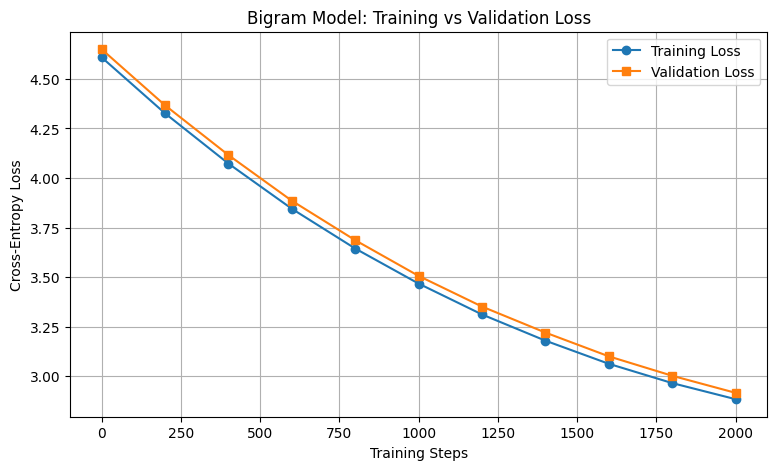

In [12]:

# 2.3: Plot Bigram Training Results

plt.figure(figsize=(9, 5))

plt.plot(
    bigram_history["steps"],
    bigram_history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    bigram_history["steps"],
    bigram_history["val_loss"],
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("Bigram Model: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


### 2.4 Bigram Text Generation

The trained Bigram model generates 500 new characters
using a newline character as the initial prompt.

The generated text will be evaluated qualitatively for
spelling, word formation, punctuation, and sentence structure.

In [13]:

# 2.4 Bigram Text Generation

prompt = "\n"

torch.manual_seed(42)

if device == "cuda":
    torch.cuda.manual_seed_all(42)

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

bigram_model.eval()

with torch.no_grad():
    generated_ids = bigram_model.generate(
        context,
        max_new_tokens=500
    )

bigram_generated_text = decode(
    generated_ids[0].tolist()
)

print("Bigram Generated Text:\n")
print(bigram_generated_text)

print("\nGenerated characters (excluding prompt):",
      len(bigram_generated_text) - len(prompt))


Bigram Generated Text:


IF3H?:Cafnt hDPEDnTERot'larmd XFarnd hk,3pbyckn,
!

I f f o-cASABKpapvwilers we bOYorgompPrAUClu.WitcoER;
IKedJvzROf laXcKEngEENigotps
bVotha!
UKESH.


D hat ght mt m:gTh;jeHeCUeVN dFiwhw-f bRunorxicesse wENTh Fz, wyesD t ee? wmitoxetpu'? m; hy?



INSThyou;BRGLONG;
Wioz h hutpuseO,kENVI wn y owe:
LUSGo be'sUSTUEB,
LqTd pY-eRpefemVht hqgososour tEEORHI woxe!gty ?RER:M tNEOMxp te s mirH?
Cos '
ORu'wsD h:nfdeV:BvoCLYIN:UKsLIDUM!asMTVQ on AR.Forily aNOJsostil?-uREOUGLUCoWknBRseUCKIOWhRYZABETZWeiKV.

Generated characters (excluding prompt): 500


### 2.5 Bigram Model Observations

The Bigram model was trained for 2,000 iterations using the Tiny Shakespeare dataset. During training, the training loss decreased from 4.6089 to 2.8835, while the validation loss decreased from 4.6497 to 2.9155. The total training and evaluation time was 7.85 seconds.

The generated sample contained 500 characters and demonstrated poor language structure. Although a few short recognizable words and punctuation marks appeared, most of the output consisted of misspelled words, inconsistent capitalization, and random character sequences. The model produced line breaks but failed to generate meaningful sentences or realistic conversations.

These results are consistent with the Bigram model's architecture, which uses only the immediately preceding character to predict the next character. As a result, the model cannot capture relationships between multiple previous characters or understand sentence-level context.

The training and validation losses decreased steadily without significant signs of overfitting. However, both losses were still decreasing after 2,000 iterations, suggesting that additional training could further improve the model's predictions.

Overall, the Bigram model provides a useful baseline for comparing the performance of the LSTM and Transformer models.

## 3. LSTM Language Model

### 3.1 LSTM Model Implementation

The Long Short-Term Memory (LSTM) model is a recurrent neural
network that processes character sequences while maintaining
hidden and cell states.

Unlike the Bigram model, the LSTM uses information from
multiple preceding characters to predict the next character.

The architecture consists of:
- Character embedding layer
- Two LSTM layers
- Linear output layer

Although LSTMs can learn sequential patterns, they may
struggle with long-range dependencies because information
must pass through recurrent states sequentially.

In [14]:

# 3.1 LSTM Language Model Implementation

class LSTMLanguageModel(nn.Module):

    def __init__(self, vocab_size,
                 embedding_dim=128,
                 hidden_dim=256,
                 num_layers=2):

        super().__init__()

        # Character embedding layer
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim
        )

        # Recurrent LSTM layers
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        # Next-character output layer
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, idx, targets=None):

        # Convert character IDs into embeddings
        x = self.embedding(idx)

        # Process character sequences
        x, _ = self.lstm(x)

        # Predict next-character logits
        logits = self.fc(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):

        for _ in range(max_new_tokens):

            # Use the most recent context
            idx_cond = idx[:, -block_size:]

            logits, _ = self(idx_cond)

            # Prediction at the last position
            logits = logits[:, -1, :]

            probs = F.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs, num_samples=1
            )

            idx = torch.cat(
                (idx, idx_next), dim=1
            )

        return idx


# Initialize LSTM model
lstm_model = LSTMLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden_dim=256,
    num_layers=2
).to(device)

# Count parameters
lstm_params = sum(
    p.numel() for p in lstm_model.parameters()
)

print("LSTM model created successfully!")
print("Total parameters:", lstm_params)
print("Device:", next(lstm_model.parameters()).device)

# Test forward pass
xb, yb = get_batch("train")

logits, loss = lstm_model(xb, yb)

print("Logits shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))


LSTM model created successfully!
Total parameters: 946625
Device: cuda:0
Logits shape: torch.Size([64, 128, 65])
Initial loss: 4.158


### 3.2 LSTM Model Training

The LSTM model is trained on the Tiny Shakespeare dataset
using the AdamW optimizer and cross-entropy loss.

The model is trained for 2,000 iterations with a batch
size of 64 and a context length of 128 characters.

Training and validation losses are evaluated every 200
iterations using 50 randomly sampled batches.

The total elapsed time, including periodic evaluation,
is recorded for comparison with the Bigram and
Transformer models.

In [15]:

# 3.2 LSTM Model Training

lstm_max_iters = 2000
lstm_learning_rate = 0.001

lstm_optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=lstm_learning_rate
)

lstm_history = {
    "steps": [],
    "train_loss": [],
    "val_loss": []
}

# Synchronize GPU before starting timer
if device == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

for step in range(lstm_max_iters + 1):

    # Evaluate periodically
    if step % eval_interval == 0:
        losses = estimate_loss(lstm_model)

        lstm_history["steps"].append(step)
        lstm_history["train_loss"].append(losses["train"])
        lstm_history["val_loss"].append(losses["val"])

        print(
            f"Step {step:4d} | "
            f"Train Loss: {losses['train']:.4f} | "
            f"Validation Loss: {losses['val']:.4f}"
        )

    if step == lstm_max_iters:
        break

    # Get training batch
    xb, yb = get_batch("train")

    # Forward pass
    logits, loss = lstm_model(xb, yb)

    # Backpropagation
    lstm_optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Gradient clipping for LSTM stability
    torch.nn.utils.clip_grad_norm_(
        lstm_model.parameters(), max_norm=1.0
    )

    lstm_optimizer.step()

# Synchronize GPU before stopping timer
if device == "cuda":
    torch.cuda.synchronize()

lstm_training_time = time.perf_counter() - start_time

print("\nLSTM Training Completed!")
print(f"Total elapsed time: {lstm_training_time:.2f} seconds")
print(f"Final training loss: {lstm_history['train_loss'][-1]:.4f}")
print(f"Final validation loss: {lstm_history['val_loss'][-1]:.4f}")


Step    0 | Train Loss: 4.1580 | Validation Loss: 4.1582
Step  200 | Train Loss: 1.9532 | Validation Loss: 1.9947
Step  400 | Train Loss: 1.6664 | Validation Loss: 1.7965
Step  600 | Train Loss: 1.5417 | Validation Loss: 1.7000
Step  800 | Train Loss: 1.4689 | Validation Loss: 1.6518
Step 1000 | Train Loss: 1.4241 | Validation Loss: 1.6088
Step 1200 | Train Loss: 1.3800 | Validation Loss: 1.5807
Step 1400 | Train Loss: 1.3561 | Validation Loss: 1.5539
Step 1600 | Train Loss: 1.3336 | Validation Loss: 1.5516
Step 1800 | Train Loss: 1.3104 | Validation Loss: 1.5362
Step 2000 | Train Loss: 1.3012 | Validation Loss: 1.5255

LSTM Training Completed!
Total elapsed time: 53.90 seconds
Final training loss: 1.3012
Final validation loss: 1.5255


In [29]:
# 3.2A: Save LSTM Model Checkpoint

import torch

torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "history": lstm_history,
    "training_time": lstm_training_time
}, "/content/lstm_checkpoint.pt")

print("LSTM checkpoint saved successfully!")

LSTM checkpoint saved successfully!


### 3.3 LSTM Training and Validation Loss Visualization

The graph illustrates the training and validation cross-entropy
losses over 2,000 training iterations.

Both losses decreased significantly during training.
The training loss reached 1.3012, while the validation
loss reached 1.5255.

The gap between training and validation loss indicates
that the model fits the training data more closely than
the unseen validation data.

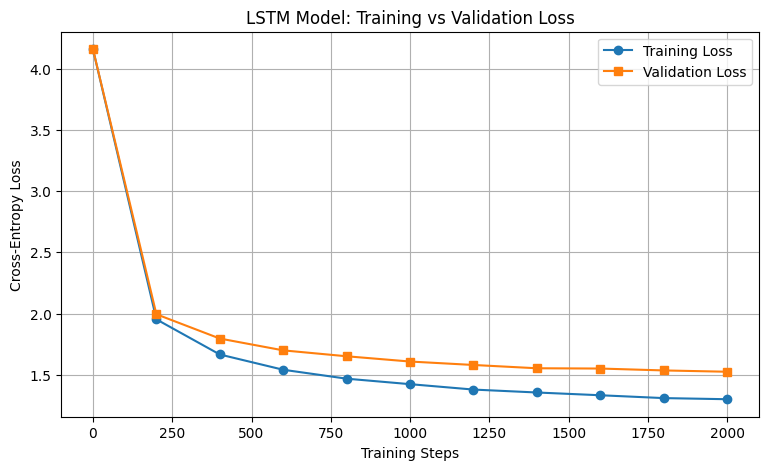

In [16]:

# 3.3 LSTM Training and Validation Loss Visualization

plt.figure(figsize=(9, 5))

plt.plot(
    lstm_history["steps"],
    lstm_history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    lstm_history["steps"],
    lstm_history["val_loss"],
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("LSTM Model: Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


### 3.4 LSTM Text Generation

The trained LSTM model generates 500 characters using a
newline character as the initial prompt.

The same initial prompt and random seed used for the Bigram
model are applied to maintain consistent generation settings.

The generated text is evaluated for word formation,
spelling, punctuation, sentence structure, and coherence.

In [17]:

# 3.4 LSTM Text Generation

# Use the same prompt as the Bigram model
prompt = "\n"

# Set random seed for reproducibility
torch.manual_seed(42)

if device == "cuda":
    torch.cuda.manual_seed_all(42)

# Convert prompt to numerical IDs
context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

# Switch model to evaluation mode
lstm_model.eval()

# Generate 500 new characters
with torch.no_grad():
    generated_ids = lstm_model.generate(
        context,
        max_new_tokens=500
    )

# Convert numerical IDs back to text
lstm_generated_text = decode(
    generated_ids[0].tolist()
)

print("LSTM Generated Text:\n")
print(lstm_generated_text)

print("\nGenerated characters (excluding prompt):",
      len(lstm_generated_text) - len(prompt))


LSTM Generated Text:


Whil as fits this servantaged it and heart:
There's no more--And, lack'd the worst, thou tenders.
Go, if is a kind folk, man, you'll stone
That an ever, that greater to answer.

LADY CAPULET:
Who high, God march, and so thee?

LUCIO:
Why? my lord, and I would have their senest: she, stay thee a
presence at the man, and speak perpech;
Let's so return Henry him your dispatting.

HENRY BOLINGBROKE:
I sa montwents of York, sir, I am Truncham!
For thine ostering unhiptors are to-night.

SICINIUS:
Pra

Generated characters (excluding prompt): 500


### 3.5 LSTM Model Observations

The LSTM model was trained for 2,000 iterations using the Tiny Shakespeare dataset. During training, the training loss decreased from 4.1580 to 1.3012, while the validation loss decreased from 4.1582 to 1.5255. The total training and evaluation time was 53.90 seconds.

The generated text consisted of 500 characters and showed a noticeable improvement in language structure compared to the Bigram model. The LSTM generated several recognizable words, phrases, and character names, including LADY CAPULET, LUCIO, HENRY BOLINGBROKE, and SICINIUS. Additionally, the model maintained dialogue formatting through line breaks and punctuation.

Nevertheless, the generated text contained grammatical mistakes, invented words, and sentences that lacked meaningful connections. Although the model learned common language patterns and Shakespeare-style dialogue structures, it struggled to generate fully coherent text.

The LSTM model performed better than the Bigram model because its hidden and cell states allow it to retain information from previous characters. Consequently, the model can identify and learn sequential patterns across multiple characters, whereas the Bigram model only considers the immediately preceding character.

Both training and validation losses continued to decrease, although a gap developed between them. The final training loss was 1.3012, while the validation loss was 1.5255, indicating that the model performed better on the training data than on unseen validation data.

Overall, the LSTM model demonstrated a significant improvement over the Bigram model in terms of validation loss and generated text quality. However, this improvement came at the cost of additional model parameters and longer training time.

## 4. Small Transformer Language Model

### 4.1 Transformer Model Implementation

The Transformer model uses causal multi-head self-attention
to learn relationships between characters in a sequence.

Unlike the Bigram model, which uses only the preceding
character, and the LSTM, which processes information
sequentially, the Transformer uses attention to identify
relevant positions within the available context.

The architecture includes:
- Token embeddings
- Learned positional embeddings
- Four Transformer blocks
- Four attention heads
- Causal masking
- Feedforward networks
- Residual connections and layer normalization
- Final linear output layer

Causal masking prevents the model from accessing future
characters during next-character prediction.

In [18]:

# 4.1 Small Transformer Model Implementation

class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.1):
        super().__init__()

        assert n_embd % n_head == 0

        self.n_head = n_head
        self.head_dim = n_embd // n_head

        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # Lower-triangular causal attention mask
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(block_size, block_size))
        )

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Attention scores
        scores = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)

        # Prevent looking at future positions
        scores = scores.masked_fill(
            self.mask[:T, :T] == 0, float("-inf")
        )

        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        return self.resid_dropout(self.proj(out))


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(
            n_embd, n_head, block_size, dropout
        )

        self.ln2 = nn.LayerNorm(n_embd)

        self.ffwd = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        block_size=128,
        n_embd=128,
        n_head=4,
        n_layer=4,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(
            *[
                TransformerBlock(
                    n_embd, n_head, block_size, dropout
                )
                for _ in range(n_layer)
            ]
        )

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > self.block_size:
            raise ValueError("Sequence exceeds context length")

        token_emb = self.token_embedding(idx)

        positions = torch.arange(T, device=idx.device)
        position_emb = self.position_embedding(positions)

        x = token_emb + position_emb

        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)

            idx = torch.cat((idx, idx_next), dim=1)

        return idx


# Initialize Transformer
transformer_model = TransformerLanguageModel(
    vocab_size=vocab_size,
    block_size=block_size,
    n_embd=128,
    n_head=4,
    n_layer=4,
    dropout=0.1
).to(device)

# Count parameters
transformer_params = sum(
    p.numel() for p in transformer_model.parameters()
)

print("Transformer model created successfully!")
print("Total parameters:", transformer_params)
print("Device:", next(transformer_model.parameters()).device)

# Test forward pass
xb, yb = get_batch("train")

logits, loss = transformer_model(xb, yb)

print("Logits shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))


Transformer model created successfully!
Total parameters: 826433
Device: cuda:0
Logits shape: torch.Size([64, 128, 65])
Initial loss: 4.3034


### 4.2 Transformer Model Training

The Small Transformer model is trained on the Tiny Shakespeare
dataset for 2,000 iterations using the AdamW optimizer and
cross-entropy loss.

The model uses a batch size of 64, a context length of 128,
and a learning rate of 0.001.

Training and validation losses are evaluated every 200
iterations using 50 randomly sampled batches.

The same evaluation procedure used for the Bigram and LSTM
models is applied to maintain consistency.

The total elapsed time, including periodic evaluation,
is recorded for comparison with the other models.

In [19]:

# 4.2 Transformer Model Training

transformer_max_iters = 2000
transformer_learning_rate = 0.001

transformer_optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=transformer_learning_rate
)

transformer_history = {
    "steps": [],
    "train_loss": [],
    "val_loss": []
}

# Synchronize GPU before starting timer
if device == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

for step in range(transformer_max_iters + 1):

    # Evaluate periodically
    if step % eval_interval == 0:
        losses = estimate_loss(transformer_model)

        transformer_history["steps"].append(step)
        transformer_history["train_loss"].append(losses["train"])
        transformer_history["val_loss"].append(losses["val"])

        print(
            f"Step {step:4d} | "
            f"Train Loss: {losses['train']:.4f} | "
            f"Validation Loss: {losses['val']:.4f}"
        )

    if step == transformer_max_iters:
        break

    # Get training batch
    xb, yb = get_batch("train")

    # Forward pass
    logits, loss = transformer_model(xb, yb)

    # Backpropagation
    transformer_optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Gradient clipping for stability
    torch.nn.utils.clip_grad_norm_(
        transformer_model.parameters(),
        max_norm=1.0
    )

    transformer_optimizer.step()

# Synchronize GPU before recording time
if device == "cuda":
    torch.cuda.synchronize()

transformer_training_time = (
    time.perf_counter() - start_time
)

print("\nTransformer Training Completed!")
print(
    f"Total elapsed time: "
    f"{transformer_training_time:.2f} seconds"
)
print(
    f"Final training loss: "
    f"{transformer_history['train_loss'][-1]:.4f}"
)
print(
    f"Final validation loss: "
    f"{transformer_history['val_loss'][-1]:.4f}"
)


Step    0 | Train Loss: 4.2972 | Validation Loss: 4.2892
Step  200 | Train Loss: 2.3245 | Validation Loss: 2.3424
Step  400 | Train Loss: 1.9788 | Validation Loss: 2.0493
Step  600 | Train Loss: 1.7668 | Validation Loss: 1.8950
Step  800 | Train Loss: 1.6586 | Validation Loss: 1.8049
Step 1000 | Train Loss: 1.5793 | Validation Loss: 1.7486
Step 1200 | Train Loss: 1.5241 | Validation Loss: 1.7104
Step 1400 | Train Loss: 1.4806 | Validation Loss: 1.6712
Step 1600 | Train Loss: 1.4502 | Validation Loss: 1.6432
Step 1800 | Train Loss: 1.4229 | Validation Loss: 1.6268
Step 2000 | Train Loss: 1.4106 | Validation Loss: 1.6031

Transformer Training Completed!
Total elapsed time: 76.13 seconds
Final training loss: 1.4106
Final validation loss: 1.6031


In [20]:

# 4.2A Save Transformer Checkpoint

torch.save({
    "model_state_dict": transformer_model.state_dict(),
    "optimizer_state_dict": transformer_optimizer.state_dict(),
    "history": transformer_history,
    "training_time": transformer_training_time,
    "parameters": transformer_params,
    "iterations": transformer_max_iters
}, "/content/transformer_checkpoint.pt")

print("Transformer checkpoint saved successfully!")


Transformer checkpoint saved successfully!


### 4.3 Transformer Training and Validation Loss Visualization

The graph illustrates the training and validation cross-entropy
losses over 2,000 training iterations.

The training loss decreased from 4.2972 to 1.4106, while
the validation loss decreased from 4.2892 to 1.6031.

Both curves show consistent improvement during training.
Although the model learned meaningful patterns, its final
validation loss remained higher than that of the LSTM model.

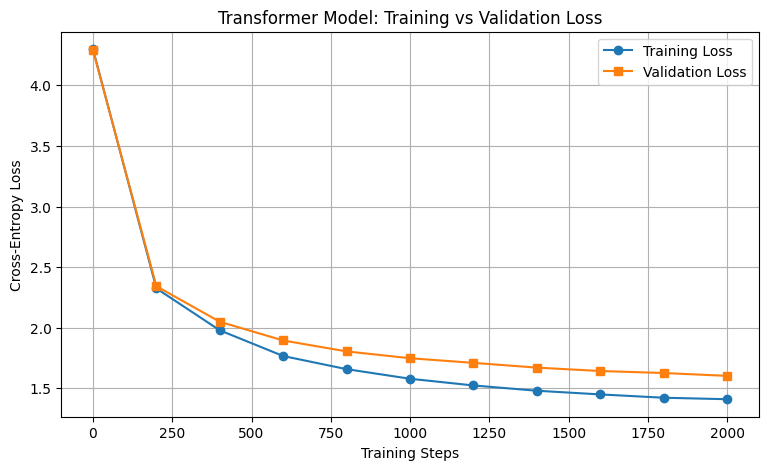

In [21]:

# 4.3 Transformer Training and Validation Loss Visualization

plt.figure(figsize=(9, 5))

plt.plot(
    transformer_history["steps"],
    transformer_history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    transformer_history["steps"],
    transformer_history["val_loss"],
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Model: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


### 4.4 Transformer Text Generation

The trained Transformer model generates 500 characters using
a newline character as the initial prompt.

The same prompt, random seed, and generation length used
for the Bigram and LSTM models are applied.

The generated text is evaluated for spelling, word formation,
sentence structure, dialogue formatting, and coherence.

In [22]:

# 4.4 Transformer Text Generation

prompt = "\n"

torch.manual_seed(42)

if device == "cuda":
    torch.cuda.manual_seed_all(42)

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

transformer_model.eval()

with torch.no_grad():
    generated_ids = transformer_model.generate(
        context,
        max_new_tokens=500
    )

transformer_generated_text = decode(
    generated_ids[0].tolist()
)

print("Transformer Generated Text:\n")
print(transformer_generated_text)

print("\nGenerated characters (excluding prompt):",
      len(transformer_generated_text) - len(prompt))


Transformer Generated Text:


If that fit any my more unred than queen,
And nought them, and be lap with cale but thine
That whether younged it die age
Angelo; what behind mean thy rest that court: have preternicies:
His wurderic subject a man, gentlemen?
This mother? my lord, and why cost cast;
Who We have she, being not and say God tear.

ESCALUS:
By, my lord?

LUCIO:
I chearts I will not so.

KING RICHARD III:
Hear should I say may despise and you
That as The coping of the asssolving--for man. Well, I have you duke not
Th

Generated characters (excluding prompt): 500


In [23]:
# 4.4A Save Transformer Generated Text
from pathlib import Path

Path("/content/transformer_sample.txt").write_text(
    transformer_generated_text,
    encoding="utf-8"
)

print("Transformer generated text saved successfully!")

Transformer generated text saved successfully!


### 4.5 Transformer Model Observations

The Small Transformer model was trained for 2,000 iterations using the Tiny Shakespeare dataset. During training, the training loss decreased from 4.2972 to 1.4106, while the validation loss decreased from 4.2892 to 1.6031. The total training and evaluation time was 76.13 seconds.

The generated text consisted of 500 characters and demonstrated recognizable Shakespeare-style language patterns. The model generated several meaningful words, short phrases, and character names such as ESCALUS, LUCIO, and KING RICHARD III. The text also maintained some dialogue formatting through line breaks and punctuation marks similar to those found in the original dataset.

However, the generated text contained grammatical errors, invented words, and sentences that lacked clear meaning. Although the model learned common language and dialogue patterns, it struggled to maintain coherence throughout the generated passage.

The Transformer uses causal self-attention to learn relationships between characters within the available context. Unlike the LSTM, which processes sequences using recurrent hidden and cell states, self-attention allows the Transformer to directly consider relevant earlier positions when predicting the next character. This provides an alternative approach to learning sequential relationships without relying on recurrent processing.

Both training and validation losses decreased consistently throughout training. The final training loss was 1.4106, while the validation loss reached 1.6031. The difference between these values indicates that the model performed better on training data than on unseen validation data.

Compared with the LSTM model, the Transformer achieved a higher validation loss of 1.6031 compared with 1.5255 and required more training and evaluation time, 85.40 seconds compared with 66.16 seconds. Although the Transformer generated recognizable dialogue patterns, the results did not demonstrate a clear improvement in generated text quality over the LSTM.

Overall, the experiment demonstrated that the Transformer could use self-attention to learn character relationships and generate structured text. However, under the training conditions used in this experiment, the LSTM achieved better validation performance with less computational time. These findings suggest that the benefits of self-attention depend on factors such as model architecture, hyperparameter configuration, training duration, and available computational resources.

## 5. Final Model Comparison and Evaluation

### 5.1 Final Results Comparison Table

This section compares the performance of the Bigram, LSTM, and Transformer models trained on the Tiny Shakespeare dataset. All three models were trained for 2,000 iterations using the same training and validation datasets, batch size of 64, and context length of 128 characters.

The comparison focuses on the number of model parameters, final training loss, final validation loss, total training and evaluation time, and generated text length.


In [24]:

# 5.1: Final Results Comparison Table

import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["Bigram", "LSTM", "Transformer"],
    "Parameters": [
        bigram_params,
        lstm_params,
        transformer_params
    ],
    "Iterations": [2000, 2000, 2000],
    "Training Loss": [
        bigram_history["train_loss"][-1],
        lstm_history["train_loss"][-1],
        transformer_history["train_loss"][-1]
    ],
    "Validation Loss": [
        bigram_history["val_loss"][-1],
        lstm_history["val_loss"][-1],
        transformer_history["val_loss"][-1]
    ],
    "Time (seconds)": [
        bigram_training_time,
        lstm_training_time,
        transformer_training_time
    ],
    "Generated Characters": [
        len(bigram_generated_text) - 1,
        len(lstm_generated_text) - 1,
        len(transformer_generated_text) - 1
    ]
})

display(comparison_df.round(4))

# Save the table for the final submission
comparison_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


,Model,Parameters,Iterations,Training Loss,Validation Loss,Time (seconds),Generated Characters
0,Bigram,4225,2000,2.8835,2.9155,7.8458,500
1,LSTM,946625,2000,1.3012,1.5255,53.8999,500
2,Transformer,826433,2000,1.4106,1.6031,76.1310,500


Model comparison saved successfully!


### 5.2 Combined Training Loss Comparison

This section compares the training loss curves of the Bigram, LSTM, and Transformer models over 2,000 training iterations. The comparison illustrates how the models learned during training and highlights differences in their convergence behavior.

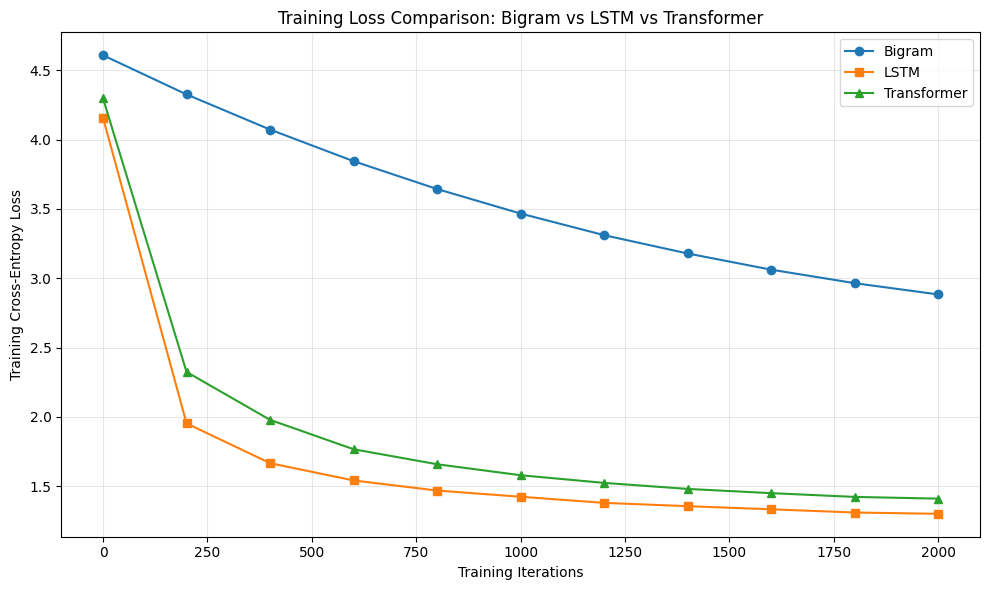

Training loss comparison graph saved successfully!


In [25]:

# 5.2: Combined Training Loss Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    bigram_history["steps"],
    bigram_history["train_loss"],
    label="Bigram",
    marker="o"
)

plt.plot(
    lstm_history["steps"],
    lstm_history["train_loss"],
    label="LSTM",
    marker="s"
)

plt.plot(
    transformer_history["steps"],
    transformer_history["train_loss"],
    label="Transformer",
    marker="^"
)

plt.title("Training Loss Comparison: Bigram vs LSTM vs Transformer")
plt.xlabel("Training Iterations")
plt.ylabel("Training Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    "/content/training_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training loss comparison graph saved successfully!")


### 5.3 Combined Validation Loss Comparison

This section compares the validation loss curves of the Bigram, LSTM, and Transformer models over 2,000 training iterations. Validation loss measures model performance on data not used for parameter updates and helps evaluate how well each model generalizes.

The comparison also provides insight into the differences in learning behavior and final validation performance across the three architectures.

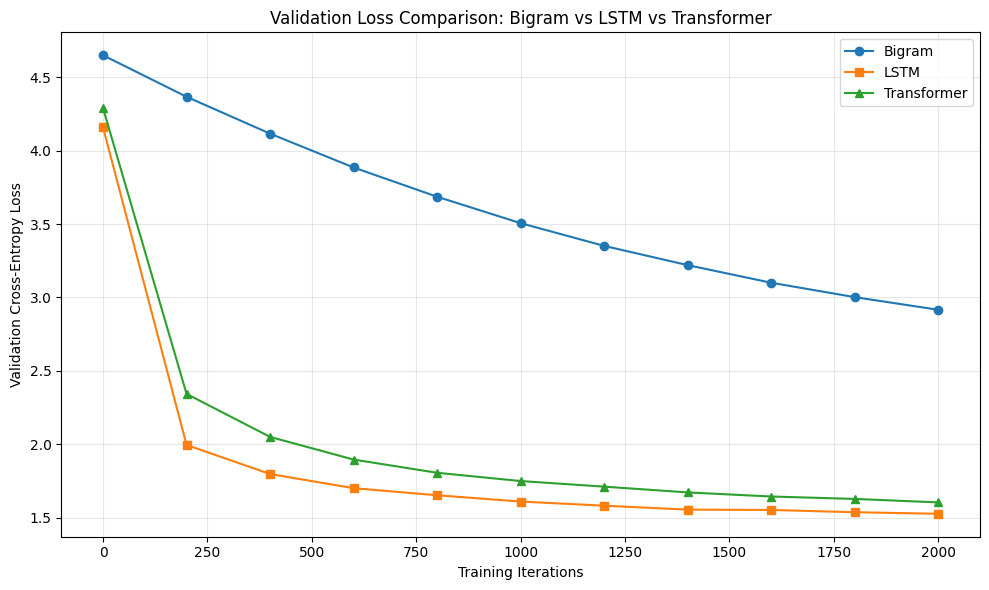

Validation loss comparison graph saved successfully!


In [26]:

# 5.3: Combined Validation Loss Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    bigram_history["steps"],
    bigram_history["val_loss"],
    label="Bigram",
    marker="o"
)

plt.plot(
    lstm_history["steps"],
    lstm_history["val_loss"],
    label="LSTM",
    marker="s"
)

plt.plot(
    transformer_history["steps"],
    transformer_history["val_loss"],
    label="Transformer",
    marker="^"
)

plt.title("Validation Loss Comparison: Bigram vs LSTM vs Transformer")
plt.xlabel("Training Iterations")
plt.ylabel("Validation Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph for submission
plt.savefig(
    "/content/validation_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Validation loss comparison graph saved successfully!")


### 5.4 Generated Text Quality Comparison

This section compares the text generated by the Bigram, LSTM, and Transformer models after 2,000 training iterations. Each model generated 500 characters using the same initial prompt.

The comparison focuses on recognizable words, grammatical structure, dialogue formatting, sentence coherence, and the ability to reproduce Shakespeare-style language patterns.

In [27]:

# 5.4: Generated Text Quality Comparison

from pathlib import Path
import pandas as pd

samples = {
    "Bigram": bigram_generated_text,
    "LSTM": lstm_generated_text,
    "Transformer": transformer_generated_text
}

# Save all generated text samples
output_dir = Path("/content/generated_samples")
output_dir.mkdir(exist_ok=True)

for model_name, generated_text in samples.items():
    file_path = output_dir / f"{model_name.lower()}_sample.txt"
    file_path.write_text(generated_text, encoding="utf-8")
    print(f"{model_name} sample saved: {file_path}")

# Create a qualitative comparison table
text_quality_df = pd.DataFrame({
    "Model": ["Bigram", "LSTM", "Transformer"],
    "Generated Characters": [
        len(text) - 1 for text in samples.values()
    ],
    "Word Structure": [
        "Poor", "Mostly recognizable", "Mostly recognizable"
    ],
    "Dialogue Formatting": [
        "Poor", "Recognizable", "Recognizable"
    ],
    "Sentence Coherence": [
        "Very low", "Limited", "Limited"
    ],
    "Overall Text Quality": [
        "Low", "Medium", "Medium"
    ]
})

display(text_quality_df)

text_quality_df.to_csv(
    "/content/text_quality_comparison.csv",
    index=False
)

print("\nText quality comparison saved successfully!")


Bigram sample saved: /content/generated_samples/bigram_sample.txt
LSTM sample saved: /content/generated_samples/lstm_sample.txt
Transformer sample saved: /content/generated_samples/transformer_sample.txt


,Model,Generated Characters,Word Structure,Dialogue Formatting,Sentence Coherence,Overall Text Quality
0,Bigram,500,Poor,Poor,Very low,Low
1,LSTM,500,Mostly recognizable,Recognizable,Limited,Medium
2,Transformer,500,Mostly recognizable,Recognizable,Limited,Medium



Text quality comparison saved successfully!


**Observations Regarding Generated Text Comparison**

The generated text samples demonstrated noticeable differences among the three models. The Bigram model produced mostly meaningless character combinations and misspelled words. It failed to generate meaningful sentences or recognizable dialogue.

The LSTM model generated more recognizable word combinations and speaker names, such as LADY CAPULET, LUCIO, and HENRY BOLINGBROKE. Despite grammatical errors and invented words, the text generated by the LSTM showed significant improvement compared with the Bigram model.

The Transformer model generated Shakespeare-style dialogue and speaker names, such as ESCALUS, LUCIO, and KING RICHARD III. Its output contained partially meaningful phrases and recognizable dialogue formatting. However, it still included invented words and sentences that lacked coherence.

Overall, the text generated by the LSTM and Transformer models was more structured than the text produced by the Bigram model. However, the generated samples did not provide clear evidence that the Transformer performed better than the LSTM in terms of text quality. Additionally, the LSTM achieved the lowest validation loss of 1.5255, compared with 1.6031 for the Transformer.

### 5.5 Model Performance Analysis and Discussion

The comparison between the Bigram, LSTM, and Transformer models revealed considerable differences in training performance, generalization ability, computational efficiency, and generated text quality. All three models were trained on the Tiny Shakespeare dataset for 2,000 iterations, using a batch size of 64 and a context length of 128 characters.

**Training and Validation Performance**

The final training and validation losses for the Bigram model were 2.8835 and 2.9155, respectively. Although both losses steadily decreased throughout training, the Bigram model performed considerably worse than the LSTM and Transformer models. This result was expected because the Bigram model uses only the immediately preceding character to predict the next character.

The final training and validation losses of the LSTM were 1.3012 and 1.5255, respectively, while those of the Transformer were 1.4106 and 1.6031. Both models demonstrated substantially better predictive performance than the Bigram model. However, the LSTM achieved better results than the Transformer under the experimental conditions.

**Training Efficiency and Model Complexity**

The Bigram model was the smallest architecture, containing only 4,225 parameters, and completed training and evaluation in 7.85 seconds. However, its simple architecture limited its predictive performance and resulted in poor generated text quality.

The LSTM model contained 946,625 parameters and required 53.90 seconds for training and evaluation. The Transformer contained 826,433 parameters and required 76.13 seconds. Although the Transformer had fewer parameters than the LSTM, it required more execution time. Therefore, the results indicate that parameter count alone does not determine computational efficiency. Architectural differences and computational operations also influence execution time.

**Quality of Generated Text**

The quality of the generated text samples also varied considerably. The Bigram model produced mostly random character sequences, misspelled words, and sentences without meaningful structure.

The LSTM and Transformer models generated recognizable Shakespeare-style dialogue, including speaker names, punctuation marks, and partially meaningful phrases. However, both models produced grammatical errors, invented words, and sentences that lacked consistent meaning.

The LSTM generated structured dialogue and achieved the lowest validation loss, while the Transformer demonstrated similar qualitative characteristics without a clear improvement in text quality.

**Overall Comparison**

The experimental results indicate that the LSTM achieved the best balance between predictive performance, computational time, and generated text quality among the three models. The Bigram model served as a simple and computationally efficient baseline, while the Transformer demonstrated the ability of causal self-attention to learn relationships between characters within the available context.

Although Transformers are widely used in language modeling tasks, this experiment showed that the LSTM performed better than the Transformer under the selected training conditions. These findings are limited to the architectures, hyperparameters, dataset, and training duration used in this experiment. Further experiments with different configurations, longer training periods, and additional computational resources could provide more insight into the potential advantages of the Transformer architecture.

In [30]:
# Create and download project ZIP

from pathlib import Path
import zipfile
from google.colab import files

base = Path("/content")
zip_path = base / "NLP_Midterm_Results.zip"

project_files = [
    "input.txt",
    "model_comparison.csv",
    "text_quality_comparison.csv",
    "training_loss_comparison.png",
    "validation_loss_comparison.png",
    "bigram_checkpoint.pt",
    "lstm_checkpoint.pt",
    "transformer_checkpoint.pt",
    "bigram_sample.txt",
    "lstm_sample.txt",
    "transformer_sample.txt"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in project_files:
        file_path = base / filename
        if file_path.exists():
            archive.write(file_path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not found at root:", filename)

    # Include samples saved inside the generated_samples folder
    sample_folder = base / "generated_samples"
    if sample_folder.exists():
        for file_path in sample_folder.glob("*.txt"):
            archive.write(
                file_path,
                arcname=f"generated_samples/{file_path.name}"
            )
            print("Added:", file_path)

files.download(str(zip_path))

Added: input.txt
Added: model_comparison.csv
Added: text_quality_comparison.csv
Added: training_loss_comparison.png
Added: validation_loss_comparison.png
Added: bigram_checkpoint.pt
Added: lstm_checkpoint.pt
Added: transformer_checkpoint.pt
Not found at root: bigram_sample.txt
Added: lstm_sample.txt
Added: transformer_sample.txt
Added: /content/generated_samples/lstm_sample.txt
Added: /content/generated_samples/transformer_sample.txt
Added: /content/generated_samples/bigram_sample.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Final Analysis and Reflection

### 6.1 Which Model Performed Best?

The LSTM network performed the best among all three models in this experiment. It recorded the lowest training loss of 1.3012 and validation loss of 1.5255 after 2,000 iterations. In comparison, the Transformer achieved a training loss of 1.4106 and validation loss of 1.6031, while the Bigram model recorded the highest losses of 2.8835 and 2.9155, respectively.

These findings indicate that the LSTM network was more effective than the other two models in learning character patterns from the Tiny Shakespeare dataset under the current training conditions. Its ability to retain information through recurrent hidden and cell states provided an advantage over the Bigram model.

### 6.2 Which Model Trained Fastest?

The Bigram model took only 7.85 seconds to complete training and evaluation, making it the fastest model. The LSTM required 53.90 seconds, while the Transformer needed 76.13 seconds.

The Bigram model trained quickly because of its simple architecture, which contained only 4,225 parameters and used an embedding-based approach. Despite having fewer parameters than the LSTM, the Transformer required more execution time. This demonstrated that computational efficiency depends on architectural characteristics and operations in addition to the number of parameters.

### 6.3 Which Model Generated the Most Realistic Text?

Both the LSTM and Transformer networks generated text that was more realistic than the Bigram model's output. Both produced recognizable Shakespeare-style dialogue, speaker names, punctuation, and partially meaningful phrases.

The Bigram model generated mostly meaningless character sequences without recognizable sentence structures. The LSTM produced dialogue containing speaker names such as LADY CAPULET and HENRY BOLINGBROKE, while the Transformer generated names such as ESCALUS and KING RICHARD III.

Although both models produced grammatically incorrect sentences and invented words, the LSTM's generated text appeared at least as realistic as the Transformer's output. The LSTM also achieved a lower validation loss, indicating better next-character prediction performance. However, comparing only one generated sample from each model was insufficient to establish a definitive difference in generated text quality.

### 6.4 What Did the Transformer Improve Compared with the Other Models?

The Transformer introduced causal self-attention, allowing it to consider different positions within the preceding context when predicting the next character.

Compared with the Bigram model, the Transformer achieved a substantially lower final validation loss of 1.6031 versus 2.9155. In addition, the Transformer produced more recognizable words, structured dialogue, and Shakespeare-style language patterns.

However, compared with the LSTM, the Transformer did not achieve a lower validation loss or faster execution in this experiment. The main architectural advantage of the Transformer was its self-attention mechanism, which provided an alternative approach to representing contextual information without relying on recurrent hidden states.

### 6.5 Was the Transformer's Improvement Worth the Added Complexity?

The Transformer provided a substantial improvement over the Bigram model in terms of predictive performance and generated text structure. Nevertheless, it did not outperform the LSTM under the training conditions used in this experiment.

The LSTM achieved a lower validation loss of 1.5255 compared with 1.6031 for the Transformer and required less time for training and evaluation. Therefore, in this particular experiment, the additional complexity of the Transformer did not provide a measurable performance advantage over the LSTM.

However, this finding does not indicate that Transformers are generally inferior to LSTMs. Different architectures, larger datasets, longer training periods, and improved hyperparameter configurations could produce different results.

### 6.6 What Did I Learn About Attention?

This experiment provided insight into the differences between attention mechanisms and traditional recurrent approaches to language modeling.

While the Bigram model considers only the immediately preceding character, the LSTM carries information through a sequence using hidden and cell states. In contrast, the Transformer uses self-attention to combine information from earlier positions within its context window.

Through this experiment, I learned that self-attention offers a flexible way to represent relationships between characters. However, using attention does not automatically guarantee better validation performance or more coherent text generation.

The results also demonstrated the importance of comparing models under consistent experimental conditions rather than assuming that a more sophisticated architecture will always produce better results.

### 6.7 Overall Reflection

This experiment provided hands-on experience in designing, training, and evaluating three different language modeling architectures for next-character prediction.

The Bigram model demonstrated the limitations of character prediction without broader context. The LSTM helped me understand the benefits of recurrent memory in language modeling, while the Transformer introduced another approach to learning contextual relationships through self-attention.

The experiment also emphasized the importance of evaluating multiple factors, including training loss, validation loss, execution time, and generated text quality. Overall, I learned that model performance depends on the architecture, training configuration, dataset characteristics, and available computational resources rather than model complexity alone.